# BN4601A Trial — Mass **Detection** (Bounding Boxes) vs. the Deployed Classifier

Self-contained experiment. Nothing here touches the parent project: the dataset is built into `detection_trial/det_dataset/`, training runs land in `detection_trial/runs/`, and the deployed classifier (`cls_dataset/`, the root `runs/`, `space_deploy/`) is left exactly as it is.

---

## The question

The deployed model is an **image classifier**: whole mammogram in, P(malignant) out, with no indication of *where* it is looking. A **detector** instead predicts a bounding box around each suspicious mass and labels that box benign or malignant.

Detection is the more ambitious task and the more clinically useful output — a radiologist can see and dispute a localisation, which a bare probability does not allow. But it is a strictly harder learning problem on the *same* 979 training mammograms: the model must now also learn *where*, from roughly one box per image, and the benign/malignant call has to be made from a region proposal rather than the whole breast. It can very reasonably come out **worse** on the benign/malignant decision the assignment is graded on.

So this notebook is built to *measure* that trade-off rather than assume it.

## What is held constant, so the comparison is fair

| Held constant | Value (identical to the classifier) |
| --- | --- |
| Case selection | CBIS-DDSM **mass** cases only (calcifications were tested and rejected) |
| Split | patient-level 80/20 train/val from the official train CSV, `seed=42` |
| Test set | the official CBIS-DDSM test CSV (361 images), never seen during training |
| Preprocessing | full mammogram resized to 640x640, JPEG quality 95 |
| Backbone scale | `yolo11s` (same 's' size as `yolo11s-cls`) |
| Augmentation philosophy | intensity/colour jitter off, flips on |

Step 4 deliberately re-seeds immediately before the patient shuffle so the **same patients** land in train and val as in the classifier run.

## What to expect

Whole-mammogram mass detection on CBIS-DDSM is hard; published two-class results typically sit around mAP@50 0.2–0.45. The usual pattern is that **localisation works noticeably better than characterising the mass once found** — the model puts a box in the right place but is unsure whether the mass is benign or malignant. Watch for exactly that split in Step 8's per-class AP.

## How to decide whether to adopt it

Step 9 is the decisive cell. It scores the detector on **exactly the classifier's task** (image-level P(malignant) = confidence of its most confident malignant box) using the same AUC / sensitivity / specificity at a validation-tuned threshold. Rough decision rule:

* **AUC within ~0.03 of 0.767** — adopt the detector: localisation comes essentially for free and makes a much stronger report.
* **AUC meaningfully lower** — keep the classifier as the graded deliverable and present this notebook as a documented negative experiment, which is worth marks in its own right (same shape of finding as the rejected calcification experiment).

---

### Workflow
1. Imports and environment check.
2. Link clinical metadata to the JPEGs on disk.
3. Group every lesion mask by its full mammogram.
4. Patient-level split, mask -> bounding box conversion, export in YOLO detection format.
5. Write `data.yaml`.
6. Visual sanity check of the generated boxes.
7. Train `yolo11s` detection, 70 epochs.
8. Detection metrics on the held-out test set (mAP@50, mAP@50-95, per-class AP).
9. **Apples-to-apples comparison against the deployed classifier.**
10. Visual check: predicted boxes vs. ground truth.
11. Local Gradio demo with bounding boxes.
12. Verdict and next steps.

### Step 1: Imports, Paths and Environment Check

Same libraries as the classifier notebook, plus two additions:

* **Locating the project root**, because this notebook lives one folder down and the data (`csv/`, `jpeg/`) sits in the parent.
* **Every shared name defined up front** — the dataset and runs folders, `data.yaml`, the class map, and the `YOLO` import. If the kernel restarts after training, run this cell and skip straight to Step 8.

In [11]:
import os
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

# Locate the folder holding csv/ and jpeg/, whether this notebook is run from
# detection_trial/ (normal) or from the project root.
CWD = Path.cwd()
PROJECT_ROOT = CWD if (CWD / 'csv').exists() else CWD.parent
if not (PROJECT_ROOT / 'csv').exists():
    raise FileNotFoundError(
        'Could not find the csv/ folder. Open this notebook from '
        'BN4601a/detection_trial/ (or from BN4601a/).'
    )

# Defined once here so a restarted kernel can run this cell and skip straight to Step 8.
# Anchored to the trial folder, so Step 4's rmtree can never reach outside it.
TRIAL_DIR  = PROJECT_ROOT / 'detection_trial'
OUTPUT_DIR = TRIAL_DIR / 'det_dataset'
DATA_YAML  = OUTPUT_DIR / 'data.yaml'
RUNS_DIR   = TRIAL_DIR / 'runs'

CLASS_NAMES  = {0: 'benign', 1: 'malignant'}
MALIGNANT_ID = 1

random.seed(42)
np.random.seed(42)

print('Project root  :', PROJECT_ROOT)
print('Dataset       :', OUTPUT_DIR)
print('Runs          :', RUNS_DIR)
print('PyTorch       :', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU           :', torch.cuda.get_device_name(0))
    print('VRAM (GB)     :', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))

Project root  : c:\Users\Claeb\anaconda3\BN4601a
Dataset       : c:\Users\Claeb\anaconda3\BN4601a\detection_trial\det_dataset
Runs          : c:\Users\Claeb\anaconda3\BN4601a\detection_trial\runs
PyTorch       : 2.11.0+cu128
CUDA available: True
GPU           : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM (GB)     : 6.0


### Step 2: Load Metadata & Map Mammograms to Their ROI Masks

Identical linking logic to the classifier notebook, so both experiments draw from the same image pool:

* `mass_case_description_{train,test}_set.csv` — one row per **lesion**, with the pathology label.
* `dicom_info.csv` — maps each DICOM `SeriesInstanceUID` to an actual `.jpg` on disk.
* Each case has a **full mammogram** series and an **ROI mask** series; we need both (the mask is where the bounding box comes from).

**Mass cases only.** Adding calcification cases roughly doubled the training pool but was tested and rejected in the main notebook (test AUC fell 0.671 -> 0.590). That decision is inherited here so the comparison is not confounded by a different dataset.

In [3]:
CSV_DIR = PROJECT_ROOT / 'csv'

df_train_meta = pd.read_csv(CSV_DIR / 'mass_case_description_train_set.csv')
df_test_meta  = pd.read_csv(CSV_DIR / 'mass_case_description_test_set.csv')
df_dicom      = pd.read_csv(CSV_DIR / 'dicom_info.csv')

# dicom_info.csv stores Kaggle-style paths ('CBIS-DDSM/jpeg/<uid>/<file>.jpg').
# Rewrite them as absolute paths so this notebook works from detection_trial/.
df_dicom['local_path'] = df_dicom['image_path'].str.replace('CBIS-DDSM/jpeg/', 'jpeg/', regex=False)
df_dicom['abs_path']   = df_dicom['local_path'].apply(lambda p: str(PROJECT_ROOT / p))

dicom_lookup = df_dicom.set_index(['SeriesInstanceUID', 'SeriesDescription'])['abs_path'].to_dict()

def extract_series_uid(path_str):
    """Pull the SeriesInstanceUID out of a metadata path column."""
    parts = str(path_str).strip().split('/')
    return parts[-2] if len(parts) >= 3 else None

def map_pathology_to_class(pathology_str):
    """BENIGN and BENIGN_WITHOUT_CALLBACK -> 0, MALIGNANT -> 1."""
    return 1 if 'MALIGNANT' in str(pathology_str).strip().upper() else 0

print('Mass-case metadata loaded:')
print(f'  train lesion rows: {len(df_train_meta)}')
print(f'  test lesion rows:  {len(df_test_meta)}')
print('Classes: 0 -> benign, 1 -> malignant')

Mass-case metadata loaded:
  train lesion rows: 1318
  test lesion rows:  378
Classes: 0 -> benign, 1 -> malignant


### Step 3: Group Every Lesion by Its Full Mammogram

A mammogram can carry more than one lesion, and each lesion has its own mask. The classifier collapsed these to a single image-level label; the detector **keeps them all**, since each becomes one bounding box — this is the first place the two pipelines genuinely diverge.

The patient ID is recorded alongside each image so Step 4 can split by patient rather than by image.

In [4]:
def group_cases_by_image(df_meta):
    """Map each full mammogram to its list of lesion masks, plus its patient ID."""
    image_to_lesions = {}
    image_to_patient = {}
    seen_pairs = set()

    for _, row in df_meta.iterrows():
        full_uid = extract_series_uid(row['image file path'])
        roi_uid  = extract_series_uid(row['ROI mask file path'])

        full_img_path = dicom_lookup.get((full_uid, 'full mammogram images'))
        roi_img_path  = dicom_lookup.get((roi_uid, 'ROI mask images'))

        if not full_img_path or not roi_img_path:
            continue
        if not os.path.exists(full_img_path) or not os.path.exists(roi_img_path):
            continue

        # A duplicated CSV row would otherwise write the identical box twice.
        if (full_img_path, roi_img_path) in seen_pairs:
            continue
        seen_pairs.add((full_img_path, roi_img_path))

        image_to_lesions.setdefault(full_img_path, []).append({
            'roi_path': roi_img_path,
            'class_id': map_pathology_to_class(row['pathology']),
        })
        image_to_patient[full_img_path] = row['patient_id']

    return image_to_lesions, image_to_patient

train_cases_map, train_patient_map = group_cases_by_image(df_train_meta)
test_cases_map,  test_patient_map  = group_cases_by_image(df_test_meta)

lesions_train = sum(len(v) for v in train_cases_map.values())
lesions_test  = sum(len(v) for v in test_cases_map.values())

print(f'Train pool: {len(train_cases_map):4d} mammograms / {lesions_train:4d} lesions')
print(f'Test  pool: {len(test_cases_map):4d} mammograms / {lesions_test:4d} lesions')
print(f'Mean lesions per image: {(lesions_train + lesions_test) / (len(train_cases_map) + len(test_cases_map)):.2f}')

Train pool: 1231 mammograms / 1318 lesions
Test  pool:  361 mammograms /  378 lesions
Mean lesions per image: 1.07


### Step 4: Patient-Level Split + Mask -> Bounding Box Export

#### The split (identical to the classifier)
CBIS-DDSM gives several images per patient (left/right breast, CC and MLO views). Splitting by *image* would put the same breast in both train and val and inflate the validation score, so the split is done at the **patient** level: 80% of training-CSV patients to train, 20% to val, with the official test CSV held out entirely. Any patient appearing in both official CSVs is dropped from train/val.

`random.seed(42)` is called again immediately before the shuffle, so the patient assignment is bit-identical to the classifier's run and Step 9's comparison is honest.

#### Mask -> box conversion
CBIS-DDSM ships no bounding boxes — it ships a binary **ROI mask** per lesion. The tightest enclosing box is the extent of the mask's white region:

```
xmin, xmax = min / max column index of mask pixels
ymin, ymax = min / max row index of mask pixels
```

converted to YOLO's normalised centre form:

```
x_center = (xmin + xmax) / 2 / mask_width
y_center = (ymin + ymax) / 2 / mask_height
width    = (xmax - xmin)     / mask_width
height   = (ymax - ymin)     / mask_height
```

All four values land in [0, 1], which is why resizing the image to 640x640 afterwards does not invalidate the label.

#### Two data-quality guards worth knowing about
These masks are stored as **lossy JPEGs**, not PNGs, and that breaks the obvious implementation:

1. **Threshold at 127, not 0.** JPEG compression leaves faint ringing noise scattered across the supposedly black background. Taking every pixel with value `> 0` therefore stretches the box out toward the whole frame on many cases — a silently corrupted label that still looks like a plausible number. The masks are genuinely binary (0 or 255), so thresholding at the midpoint recovers the true region.
2. **Normalise by the mask's own dimensions.** Not every CBIS-DDSM mask is stored at the same resolution as its full mammogram. Normalising mask pixel coordinates by the *full image's* width and height would shift and rescale every box on those cases.

Any mask that is blank after thresholding, or whose box covers more than 50% of the frame (the usual sign that a *cropped patch* was mis-filed under `ROI mask images`), is dropped and counted in the export summary. **Read that summary** — a large drop count means the pipeline, not the model, is the thing to fix next.

In [5]:
test_patient_ids  = set(test_patient_map.values())
excluded_patients = set(train_patient_map.values()) & test_patient_ids

patient_to_images = {}
for img_path, pid in train_patient_map.items():
    if pid in excluded_patients:
        continue
    patient_to_images.setdefault(pid, []).append(img_path)

# Re-seed immediately before the shuffle: the classifier shuffled this same
# patient list from a fresh seed(42) with no intervening random calls, so this
# reproduces its exact train/val patient assignment.
random.seed(42)
all_patient_ids = list(patient_to_images.keys())
random.shuffle(all_patient_ids)

split_idx = int(0.8 * len(all_patient_ids))
train_patient_ids = set(all_patient_ids[:split_idx])
val_patient_ids   = set(all_patient_ids[split_idx:])

split_dict = {
    'train': [p for pid in train_patient_ids for p in patient_to_images[pid]],
    'val':   [p for pid in val_patient_ids   for p in patient_to_images[pid]],
    'test':  list(test_cases_map.keys()),
}
combined_cases_map = {**train_cases_map, **test_cases_map}

print(f'Excluded {len(excluded_patients)} patient(s) present in both official CSVs.')
print(f'Patient-level split: {len(train_patient_ids)} train patients | {len(val_patient_ids)} val patients')
for name, paths in split_dict.items():
    print(f'  {name:5s}: {len(paths):4d} mammograms')

Excluded 0 patient(s) present in both official CSVs.
Patient-level split: 552 train patients | 139 val patients
  train:  979 mammograms
  val  :  252 mammograms
  test :  361 mammograms


In [6]:
TARGET_SIZE = (640, 640)    # same preprocessing the classifier's export used
MASK_THRESHOLD = 127        # masks are lossy JPEGs; '> 0' would catch ringing noise
MAX_BOX_AREA_FRAC = 0.5     # a 'mask' covering most of the frame is not a mask

# Clean slate: re-running this cell must replace the export, not add a second
# copy of every image under fresh indices.
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
for split in ['train', 'val', 'test']:
    (OUTPUT_DIR / 'images' / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / 'labels' / split).mkdir(parents=True, exist_ok=True)

def mask_to_yolo_box(mask_path):
    """Return ((xc, yc, w, h) normalised to [0,1], 'ok') or (None, reason)."""
    mask_arr = np.array(Image.open(mask_path).convert('L'))
    mask_h, mask_w = mask_arr.shape

    ys, xs = np.where(mask_arr > MASK_THRESHOLD)
    if len(xs) == 0:
        return None, 'blank'

    xmin, xmax = int(xs.min()), int(xs.max())
    ymin, ymax = int(ys.min()), int(ys.max())

    xc = ((xmin + xmax) / 2.0) / mask_w
    yc = ((ymin + ymax) / 2.0) / mask_h
    bw = (xmax - xmin) / mask_w
    bh = (ymax - ymin) / mask_h

    if bw * bh > MAX_BOX_AREA_FRAC:
        return None, 'oversized'

    box = (float(np.clip(xc, 0.0, 1.0)), float(np.clip(yc, 0.0, 1.0)),
           float(np.clip(bw, 0.001, 1.0)), float(np.clip(bh, 0.001, 1.0)))
    return box, 'ok'

def export_split(split_name, image_paths, cases_map):
    saved = total_boxes = 0
    per_class = {0: 0, 1: 0}
    dropped = {'blank': 0, 'oversized': 0, 'no_box_left': 0, 'error': 0}
    areas = []

    for idx, img_path in enumerate(image_paths):
        try:
            annotations = []
            for lesion in cases_map[img_path]:
                box, reason = mask_to_yolo_box(lesion['roi_path'])
                if box is None:
                    dropped[reason] += 1
                    continue
                xc, yc, bw, bh = box
                cid = lesion['class_id']
                annotations.append(f'{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}')
                per_class[cid] += 1
                areas.append(bw * bh)
                total_boxes += 1

            if not annotations:
                dropped['no_box_left'] += 1
                continue

            img = Image.open(img_path).convert('RGB').resize(TARGET_SIZE, Image.Resampling.BILINEAR)
            base = f'{split_name}_{idx:04d}'
            img.save(OUTPUT_DIR / 'images' / split_name / f'{base}.jpg', quality=95)
            (OUTPUT_DIR / 'labels' / split_name / f'{base}.txt').write_text('\n'.join(annotations) + '\n')
            saved += 1

        except Exception as exc:
            dropped['error'] += 1
            print(f'  ! {img_path}: {exc}')

    print(f'[{split_name.upper():5s}] {saved:4d} images | {total_boxes:4d} boxes '
          f'(benign {per_class[0]:3d}, malignant {per_class[1]:3d})')
    print(f'         dropped: {dropped["blank"]} blank masks, {dropped["oversized"]} oversized, '
          f'{dropped["no_box_left"]} images with no usable box, {dropped["error"]} errors')
    if areas:
        print(f'         box area as fraction of image: median {np.median(areas):.3f}, '
              f'min {np.min(areas):.4f}, max {np.max(areas):.3f}')

for split_name in ['train', 'val', 'test']:
    export_split(split_name, split_dict[split_name], combined_cases_map)

[TRAIN]  979 images | 1040 boxes (benign 523, malignant 517)
         dropped: 0 blank masks, 0 oversized, 0 images with no usable box, 0 errors
         box area as fraction of image: median 0.006, min 0.0003, max 0.077
[VAL  ]  252 images |  278 boxes (benign 158, malignant 120)
         dropped: 0 blank masks, 0 oversized, 0 images with no usable box, 0 errors
         box area as fraction of image: median 0.005, min 0.0005, max 0.050
[TEST ]  361 images |  378 boxes (benign 231, malignant 147)
         dropped: 0 blank masks, 0 oversized, 0 images with no usable box, 0 errors
         box area as fraction of image: median 0.006, min 0.0007, max 0.039


### Step 5: Write `data.yaml`

Detection training needs an explicit dataset manifest (classification did not — it inferred classes from folder names). The `path` is written absolute so training works regardless of the working directory Ultralytics happens to resolve from.

In [7]:
dataset_root = str(OUTPUT_DIR.resolve()).replace('\\', '/')

yaml_content = (
    f'path: {dataset_root}\n'
    'train: images/train\n'
    'val: images/val\n'
    'test: images/test\n'
    '\n'
    'names:\n'
    '  0: benign\n'
    '  1: malignant\n'
)

DATA_YAML.write_text(yaml_content)

print(f'Wrote {DATA_YAML}')
print('--- contents ---')
print(yaml_content)

Wrote C:\Users\Claeb\anaconda3\BN4601a\detection_trial\det_dataset\data.yaml
--- contents ---
path: C:/Users/Claeb/anaconda3/BN4601a/detection_trial/det_dataset
train: images/train
val: images/val
test: images/test

names:
  0: benign
  1: malignant



### Step 6: Visual Sanity Check ("Never Trust Labels You Haven't Seen")

This matters far more for detection than it did for classification. A wrong image-level label is one bad example; a wrong *box* teaches the model to look in the wrong place on every epoch, and the failure is invisible in the loss curve.

What a correct result looks like: a tight box around a visibly brighter, denser region — not a box around the whole breast, not a box floating in black background, not a box hugging the image border.

* 🟩 **Green** — benign lesion (class 0)
* 🟥 **Red** — malignant tumour (class 1)

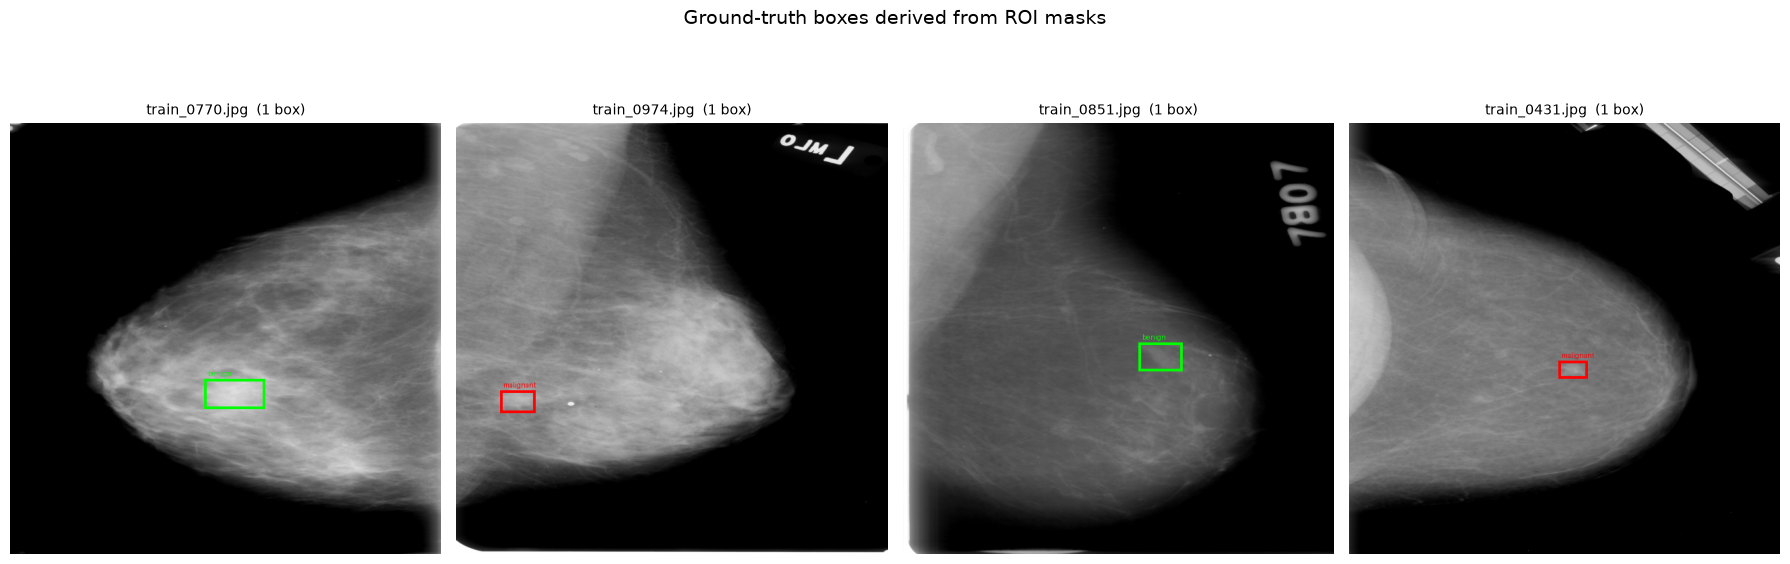

In [9]:
def inspect_yolo_labels(num_images=4, split='train'):
    """Draw the exported ground-truth boxes back onto their images."""
    img_paths = sorted((OUTPUT_DIR / 'images' / split).glob('*.jpg'))
    if not img_paths:
        print(f'No images in {split}. Run Step 4 first.')
        return

    samples = random.sample(img_paths, min(num_images, len(img_paths)))
    fig, axes = plt.subplots(1, len(samples), figsize=(4.5 * len(samples), 6))
    if len(samples) == 1:
        axes = [axes]

    class_colors = {0: (0, 255, 0), 1: (255, 0, 0)}

    for ax, img_path in zip(axes, samples):
        img = Image.open(img_path).convert('RGB')
        draw = ImageDraw.Draw(img)
        w, h = img.size

        label_file = OUTPUT_DIR / 'labels' / split / f'{img_path.stem}.txt'
        n_boxes = 0
        for line in label_file.read_text().strip().splitlines():
            cid, xc, yc, bw, bh = map(float, line.split())
            cid = int(cid)
            x0, y0 = (xc - bw / 2) * w, (yc - bh / 2) * h
            x1, y1 = (xc + bw / 2) * w, (yc + bh / 2) * h
            color = class_colors.get(cid, (255, 255, 0))
            draw.rectangle([x0, y0, x1, y1], outline=color, width=4)
            draw.text((x0 + 5, max(4, y0 - 14)), CLASS_NAMES[cid], fill=color)
            n_boxes += 1

        ax.imshow(img)
        ax.set_title(f'{img_path.name}  ({n_boxes} box)', fontsize=10)
        ax.axis('off')

    plt.suptitle('Ground-truth boxes derived from ROI masks', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

inspect_yolo_labels(4, split='train')

### Step 7: Train the Detector (Local GPU)

Fine-tune COCO-pretrained `yolo11s.pt` — the detection counterpart of the `yolo11s-cls.pt` used for the classifier, so model capacity is not a confounder in the Step 9 comparison.

**Augmentation.** The classifier's headline finding was that Ultralytics' photograph-tuned defaults actively damage grayscale mammograms. Detection has a *different* default set, and two of them matter here:

* **`mosaic=1.0` (on by default) is disabled.** Mosaic stitches four training images into one 640x640 canvas, so every mammogram is downscaled roughly 2x and four breasts appear in a grid. Masses are already small relative to the breast, and halving their pixel size on most batches works directly against the thing being learned — besides producing anatomically meaningless input. This is the single most consequential setting in this cell, and **the first thing to ablate if the results disappoint**: re-run with `mosaic=1.0, close_mosaic=10` and compare mAP@50. On small datasets mosaic sometimes wins despite the theory, so it is worth the second run rather than an assumption.
* **`degrees`, `shear`, `perspective` stay at 0.** A sheared or rotated breast is not a view a mammography unit can produce, and mass margin and shape — the actual diagnostic features — are exactly what those transforms distort.

Kept on: `fliplr` and `flipud` (left and right breasts are already mirror images of each other, and breast tissue has no canonical up/down orientation) plus a gentle `translate`/`scale`, which move the lesion around without fabricating tissue.

**Budget.** `epochs=70` with `patience=20`. On this dataset the classifier stopped itself at epoch 29 of a 100-epoch budget, so 70 is very likely a ceiling that never binds — patience is what will actually end the run. `batch=8` keeps `yolo11s` at 640px inside the 6 GB of an RTX 4050; raise it if you have more VRAM. Expect roughly 20–40 s per epoch, so 15–45 minutes depending on where early stopping lands.

`workers=0` is not optional on Windows inside Jupyter — multiprocess DataLoader workers hang there.

In [10]:
det_model = YOLO('yolo11s.pt')   # COCO-pretrained detector; downloads on first run

train_results = det_model.train(
    data=str(DATA_YAML),
    epochs=70,
    imgsz=640,
    batch=8,               # fits yolo11s @ 640 in 6 GB VRAM; raise if you have headroom
    device=0,
    seed=42,
    patience=20,           # end the run once val mAP plateaus
    workers=0,             # multiprocess DataLoader workers hang on Windows in Jupyter
    project=str(RUNS_DIR),
    name='cbis_ddsm_det',
    cos_lr=True,

    # --- augmentation OFF: corrupts or dilutes the diagnostic signal ---
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,   # grayscale X-ray: colour jitter only perturbs intensity
    mosaic=0.0,                        # 4-image stitching halves lesion size (see markdown above)
    mixup=0.0, cutmix=0.0, copy_paste=0.0,
    degrees=0.0, shear=0.0, perspective=0.0,

    # --- augmentation ON: geometry that preserves the signal ---
    fliplr=0.5, flipud=0.5,
    translate=0.1, scale=0.2,
)

print('\nBest weights:', det_model.trainer.best)
print('Inspect runs/cbis_ddsm_det/train_batch0.jpg to confirm the augmented images')
print('are still intact mammograms with correctly placed boxes.')

New https://pypi.org/project/ultralytics/8.4.154 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.146  Python-3.11.16 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Claeb\anaconda3\BN4601a\detection_trial\det_dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=70, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, ma

### Step 8: Detection Metrics on the Held-Out Test Set

> **Kernel restarted since training?** Run Step 1, then continue from here. This cell picks up the newest `best.pt` in `detection_trial/runs/` on its own. Don't re-run Step 4: it deletes and rebuilds the dataset.

These numbers are **not** comparable to the classifier's — that is what Step 9 is for. They answer a different question: *does the model put a box in the right place with the right label?*

* **mAP@50** — mean average precision counting a box correct when it overlaps ground truth at IoU >= 0.5. The headline detection number.
* **mAP@50-95** — the same, averaged over IoU thresholds 0.50 to 0.95. It punishes loose boxes and is always substantially lower; for a soft-edged mass with no crisp boundary, a low value here is expected and not very meaningful clinically.
* **Precision / Recall** — at the model's own operating point, how many predicted boxes were real, and how many real masses were found.
* **Per-class AP** — the important diagnostic. If `benign` and `malignant` AP are both low and similar, the model is failing to **localise**. If localisation looks reasonable but one class collapses, the model finds masses yet cannot **characterise** them — which is precisely where a detector loses to a classifier on the graded task.

In [12]:
# Resolve which weights to evaluate: this session's run if Step 7 just ran,
# otherwise the newest cbis_ddsm_det* run on disk.
try:
    best_det_path = str(det_model.trainer.best)
except NameError:
    candidates = sorted(RUNS_DIR.glob('cbis_ddsm_det*/weights/best.pt'),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError('No best.pt under detection_trial/runs/. Run Step 7 first.')
    best_det_path = str(candidates[0])

print('Using weights:', best_det_path)
best_det = YOLO(best_det_path)

metrics = best_det.val(
    data=str(DATA_YAML),
    split='test',
    imgsz=640,
    workers=0,
    verbose=False,
)

print('\n--- Detection metrics, held-out test set ---')
print(f'mAP@50     : {metrics.box.map50:.3f}')
print(f'mAP@50-95  : {metrics.box.map:.3f}')
print(f'Precision  : {metrics.box.mp:.3f}')
print(f'Recall     : {metrics.box.mr:.3f}')

print('\nPer class:')
for i, class_idx in enumerate(metrics.box.ap_class_index):
    name = best_det.names[int(class_idx)]
    print(f'  {name:10s} AP@50 {metrics.box.ap50[i]:.3f} | AP@50-95 {metrics.box.ap[i]:.3f}')

Using weights: C:\Users\Claeb\anaconda3\BN4601a\detection_trial\runs\cbis_ddsm_det\weights\best.pt
Ultralytics 8.4.146  Python-3.11.16 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 157.237.8 MB/s, size: 50.0 KB)
val: Scanning C:\Users\Claeb\anaconda3\BN4601a\detection_trial\det_dataset\labels\test... 361 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 361/361 1.6Kit/s 0.2s<0.1s
val: New cache created: C:\Users\Claeb\anaconda3\BN4601a\detection_trial\det_dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.8it/s 6.0s0.3s
                   all        361        378      0.464      0.471      0.438      0.181
Speed: 0.3ms preprocess, 8.0ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to C:\Users\Claeb\anaconda3\BN4601a\de

### Step 9: The Decisive Comparison — Same Task, Same Images, Same Metrics

A detector and a classifier cannot be compared on mAP (the classifier predicts no boxes) or on raw accuracy (different output shapes). They **can** be compared on the question the assignment actually grades: *given this mammogram, how likely is malignancy?*

The detector's answer is taken as the **confidence of its most confident malignant box**, and 0.0 when it predicts no malignant box at all — the detector asserting there is nothing malignant here.

Two details that keep this honest:

* Predictions are collected at `conf=0.001`. AUC is a *ranking* metric, and discarding weak detections up front would throw away exactly the information it measures.
* Ground truth uses the same rule the classifier used: an image is malignant if **any** lesion on it is malignant.

The threshold is then tuned on the **validation** set for >= 85% sensitivity and applied unchanged to the test set, exactly as in the classifier notebook — neither model gets to peek at test data when choosing its operating point.

**Classifier baseline on these same 361 test images:** AUC **0.767**, sensitivity **0.786**, specificity **0.551** at its tuned threshold of 0.236.

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve)

def image_level_scores(split_name, conf=0.001, batch_size=16):
    """Reduce the detector to the classifier's task: one P(malignant) per image."""
    img_paths = sorted((OUTPUT_DIR / 'images' / split_name).glob('*.jpg'))
    y_true, y_score = [], []

    for i in range(0, len(img_paths), batch_size):
        batch = img_paths[i:i + batch_size]
        results = best_det.predict(source=[str(p) for p in batch], conf=conf,
                                   imgsz=640, verbose=False)

        for img_path, result in zip(batch, results):
            label_file = OUTPUT_DIR / 'labels' / split_name / f'{img_path.stem}.txt'
            gt_classes = [int(line.split()[0])
                          for line in label_file.read_text().strip().splitlines()]
            y_true.append(1 if MALIGNANT_ID in gt_classes else 0)

            pred_cls  = result.boxes.cls.cpu().numpy().astype(int)
            pred_conf = result.boxes.conf.cpu().numpy()
            malignant_conf = pred_conf[pred_cls == MALIGNANT_ID]
            y_score.append(float(malignant_conf.max()) if len(malignant_conf) else 0.0)

    return np.array(y_true), np.array(y_score)

y_val,  s_val   = image_level_scores('val')
y_true, y_score = image_level_scores('test')
print(f'Scored {len(y_val)} validation images and {len(y_true)} test images.')
print(f'Test images where the detector found no malignant box at all: '
      f'{int((y_score == 0.0).sum())} / {len(y_score)}')

def report(tag, y, s, thr):
    y_pred = (s >= thr).astype(int)
    print(f'\n--- {tag}  (threshold {thr:.3f}) ---')
    print(f'AUC                            : {roc_auc_score(y, s):.3f}')
    print(f'Accuracy                       : {accuracy_score(y, y_pred):.3f}')
    print(f'Sensitivity (malignant recall) : {recall_score(y, y_pred, pos_label=1, zero_division=0):.3f}')
    print(f'Specificity (benign recall)    : {recall_score(y, y_pred, pos_label=0, zero_division=0):.3f}')
    print(f'Precision (malignant)          : {precision_score(y, y_pred, pos_label=1, zero_division=0):.3f}')
    print(f'F1 (malignant)                 : {f1_score(y, y_pred, pos_label=1, zero_division=0):.3f}')
    print('Confusion matrix [rows=true, cols=pred] (0=benign, 1=malignant):')
    print(confusion_matrix(y, y_pred))

report('DETECTOR on test @ default 0.5', y_true, y_score, 0.5)

# Operating point tuned on VALIDATION only, then applied unchanged to test.
TARGET_SENSITIVITY = 0.85
fpr, tpr, thresholds = roc_curve(y_val, s_val)
reaches_target = np.where(tpr >= TARGET_SENSITIVITY)[0]
TUNED_THRESHOLD = (float(np.clip(thresholds[reaches_target[0]], 0.0, 1.0))
                   if len(reaches_target) else 0.5)

print(f'\nThreshold chosen on VALIDATION for sensitivity >= {TARGET_SENSITIVITY:.2f}: {TUNED_THRESHOLD:.3f}')
report('DETECTOR on test @ val-tuned', y_true, y_score, TUNED_THRESHOLD)

print('\n' + '=' * 62)
print('CLASSIFIER baseline, same 361 test images:')
print('  AUC 0.767 | sensitivity 0.786 | specificity 0.551  @ threshold 0.236')
print('=' * 62)

Scored 252 validation images and 361 test images.
Test images where the detector found no malignant box at all: 0 / 361

--- DETECTOR on test @ default 0.5  (threshold 0.500) ---
AUC                            : 0.725
Accuracy                       : 0.687
Sensitivity (malignant recall) : 0.276
Specificity (benign recall)    : 0.963
Precision (malignant)          : 0.833
F1 (malignant)                 : 0.415
Confusion matrix [rows=true, cols=pred] (0=benign, 1=malignant):
[[208   8]
 [105  40]]

Threshold chosen on VALIDATION for sensitivity >= 0.85: 0.049

--- DETECTOR on test @ val-tuned  (threshold 0.049) ---
AUC                            : 0.725
Accuracy                       : 0.576
Sensitivity (malignant recall) : 0.841
Specificity (benign recall)    : 0.398
Precision (malignant)          : 0.484
F1 (malignant)                 : 0.615
Confusion matrix [rows=true, cols=pred] (0=benign, 1=malignant):
[[ 86 130]
 [ 23 122]]

CLASSIFIER baseline, same 361 test images:
  AUC 0.767 |

### Step 10: Visual Check — Predictions vs. Ground Truth

Metrics hide the failure *mode*. Look for which of these is happening, because they call for different fixes:

* box in roughly the right place, wrong class → a characterisation problem, not a localisation one;
* many confident boxes on normal tissue → too low a confidence threshold, or the model latching onto dense tissue generally;
* no boxes at all → under-trained, or the confidence threshold is above everything it produces.

**White** = ground truth · **green** = predicted benign · **red** = predicted malignant.

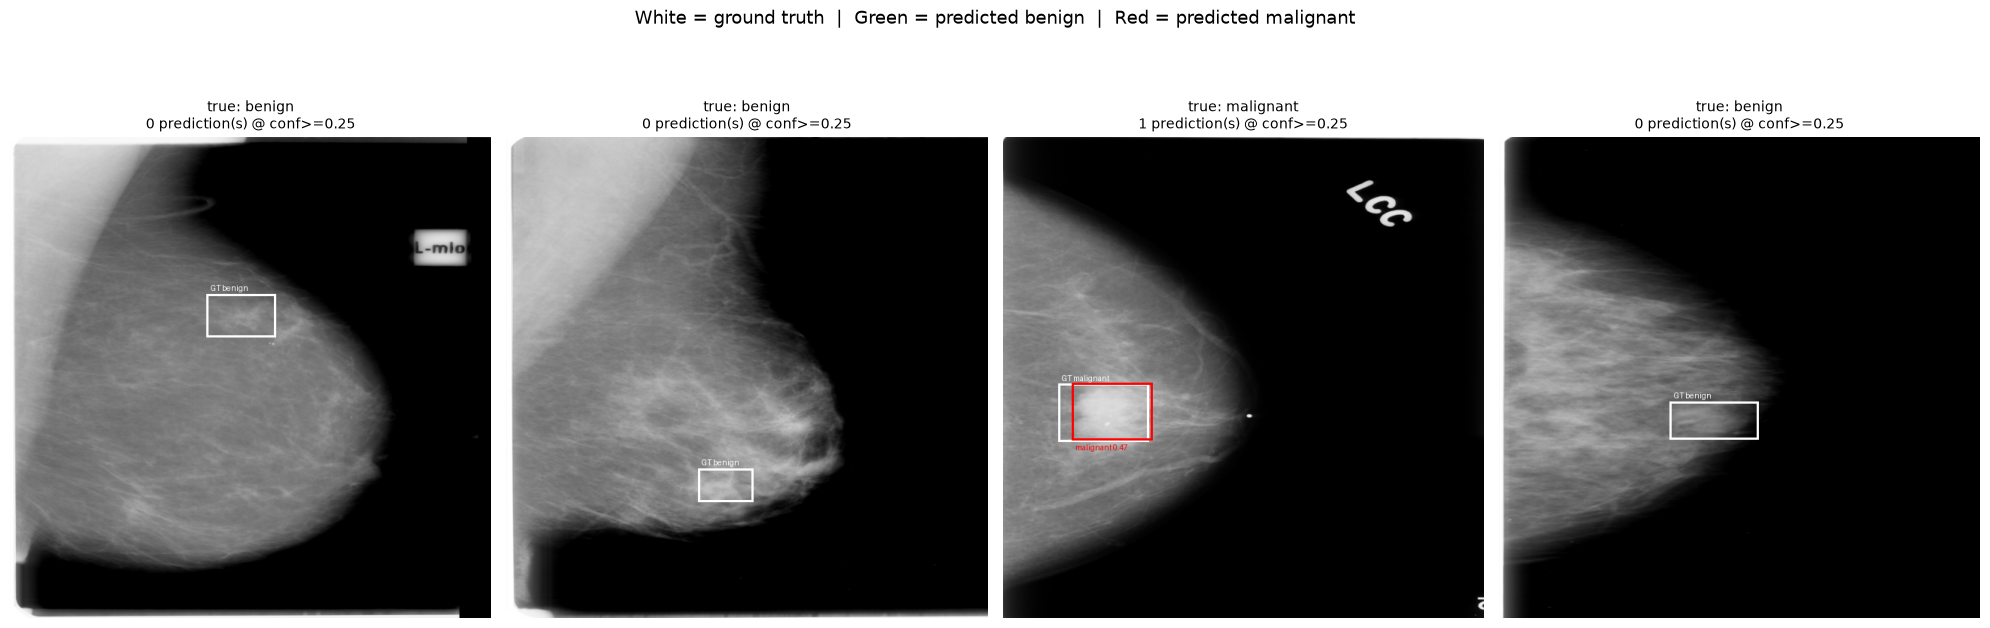

In [14]:
def show_detections(num_images=4, conf=0.25):
    """Overlay ground-truth (white) and predicted (green/red) boxes on test images."""
    img_paths = sorted((OUTPUT_DIR / 'images' / 'test').glob('*.jpg'))
    samples = random.sample(img_paths, min(num_images, len(img_paths)))

    fig, axes = plt.subplots(1, len(samples), figsize=(5 * len(samples), 6.5))
    if len(samples) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, samples):
        img = Image.open(img_path).convert('RGB')
        draw = ImageDraw.Draw(img)
        w, h = img.size

        label_file = OUTPUT_DIR / 'labels' / 'test' / f'{img_path.stem}.txt'
        gt_names = []
        for line in label_file.read_text().strip().splitlines():
            cid, xc, yc, bw, bh = map(float, line.split())
            x0, y0 = (xc - bw / 2) * w, (yc - bh / 2) * h
            x1, y1 = (xc + bw / 2) * w, (yc + bh / 2) * h
            draw.rectangle([x0, y0, x1, y1], outline=(255, 255, 255), width=3)
            draw.text((x0 + 5, max(4, y0 - 14)), f'GT {CLASS_NAMES[int(cid)]}', fill=(255, 255, 255))
            gt_names.append(CLASS_NAMES[int(cid)])

        result = best_det.predict(source=str(img_path), conf=conf, imgsz=640, verbose=False)[0]
        for box, cid, cnf in zip(result.boxes.xyxy.cpu().numpy(),
                                 result.boxes.cls.cpu().numpy().astype(int),
                                 result.boxes.conf.cpu().numpy()):
            color = (255, 0, 0) if cid == MALIGNANT_ID else (0, 255, 0)
            draw.rectangle(box.tolist(), outline=color, width=3)
            draw.text((box[0] + 5, min(h - 14, box[3] + 4)),
                      f'{CLASS_NAMES[cid]} {cnf:.2f}', fill=color)

        ax.imshow(img)
        ax.set_title(f'true: {", ".join(gt_names)}\n{len(result.boxes)} prediction(s) @ conf>={conf}',
                     fontsize=10)
        ax.axis('off')

    plt.suptitle('White = ground truth  |  Green = predicted benign  |  Red = predicted malignant',
                 fontsize=13, y=1.04)
    plt.tight_layout()
    plt.show()

show_detections(4, conf=0.25)

### Step 11: Local Gradio Demo with Bounding Boxes

The interface a detection Space would expose. Two differences from the deployed classifier's app: the output is an **annotated image** rather than a probability bar, and a **confidence slider** is exposed — detection has no equivalent of the classifier's single fixed referral threshold, since each box carries its own confidence.

The slider is genuinely useful for a screening aid: a reader can raise it to see only the model's strongest calls, or lower it to surface faint candidates. Default 0.25 is Ultralytics' convention, not a tuned clinical operating point.

In [15]:
import gradio as gr

def detect_mammogram(image, conf_threshold):
    if image is None:
        return None, 'Upload a mammogram to see a result.'

    result = best_det.predict(source=image, conf=conf_threshold, imgsz=640, verbose=False)[0]
    annotated = Image.fromarray(result.plot()[:, :, ::-1])   # .plot() returns BGR

    if len(result.boxes) == 0:
        summary = ('### No mass detected\n'
                   f'Nothing above the {conf_threshold:.0%} confidence threshold. '
                   'Lower the slider to surface weaker candidates.')
        return annotated, summary

    pred_cls  = result.boxes.cls.cpu().numpy().astype(int)
    pred_conf = result.boxes.conf.cpu().numpy()
    malignant_conf = pred_conf[pred_cls == MALIGNANT_ID]

    if len(malignant_conf):
        header = (f'### ⚠\ufe0f FLAG FOR REVIEW\n'
                  f'Most confident malignant box: **{malignant_conf.max():.1%}**')
    else:
        header = ('### ✅ Mass found, none called malignant\n'
                  'Every box above the threshold was classified benign.')

    lines = [f'- **{CLASS_NAMES[c]}** box, confidence {v:.1%}'
             for c, v in zip(pred_cls, pred_conf)]
    disclaimer = ('\n\nBoxes show where the model is looking, which a bare probability '
                  'cannot. Treat a box as a prompt to look, not as a diagnosis.')

    return annotated, header + '\n\n' + '\n'.join(lines) + disclaimer

example_imgs = [[str(p), 0.25]
                for p in sorted((OUTPUT_DIR / 'images' / 'test').glob('*.jpg'))[:3]]

demo = gr.Interface(
    fn=detect_mammogram,
    inputs=[
        gr.Image(type='pil', label='Upload Screening Mammogram'),
        gr.Slider(minimum=0.05, maximum=0.90, value=0.25, step=0.05,
                  label='Confidence Threshold'),
    ],
    outputs=[
        gr.Image(type='pil', label='Detected Masses'),
        gr.Markdown(label='Triage Summary'),
    ],
    title='AI Perception System: Breast Cancer Mass Detection on Mammography',
    description=(
        'Upload a full screening mammogram to localise suspicious masses and label each '
        'as benign or malignant.\n\n'
        '**Educational demonstration only — not a medical device, and not for diagnosis '
        'or clinical decision-making.** (BN4601A trial model)'
    ),
    examples=example_imgs,
)

demo.launch(share=False)

c:\Users\Claeb\anaconda3\envs\bn4601\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


### Step 12: Verdict — Fill This In After Running

| Metric (held-out test, 361 images) | Deployed classifier | This detector |
| --- | --- | --- |
| AUC (image-level) | 0.767 | |
| Sensitivity @ tuned threshold | 0.786 | |
| Specificity @ tuned threshold | 0.551 | |
| mAP@50 | n/a (predicts no boxes) | |
| AP@50 benign / malignant | n/a | / |
| Localises the lesion | no | yes |

**If the detector's AUC holds up (within roughly 0.03):** adopt it. Copy the weights somewhere new rather than overwriting the working Space —

```python
import shutil
from pathlib import Path

best = sorted(Path('runs').rglob('best.pt'), key=lambda p: p.stat().st_mtime)[-1]
Path('../space_deploy_det').mkdir(exist_ok=True)
shutil.copy(best, '../space_deploy_det/best.pt')
```

then adapt `space_deploy/app.py` into that folder using the Step 11 function (`gr.Image` output plus a confidence slider, instead of `gr.Label` plus a fixed threshold). Leave the existing `space_deploy/` untouched until the new Space is verified working — a broken Space costs more marks than a less ambitious one.

**If it does not hold up:** keep the classifier as the graded deliverable and write this up as a second documented negative experiment, alongside the rejected calcification run. *"We tested localisation and it cost 0.0X AUC on the clinical decision, so we shipped the classifier"* is a stronger report than never having tried, and it pre-empts the obvious question of why a detection model was not used for a detection-shaped problem.

**Either way, report the per-class AP from Step 8.** *"The model localises masses at AP@50 0.XX but separates benign from malignant at only 0.YY"* is a genuinely informative finding about the dataset and the task, not merely about this model — and it is the honest answer to whether detection adds real capability here or just adds complexity.

#### Obvious follow-ups, cheapest first
1. **Re-run with `mosaic=1.0, close_mosaic=10`** (Step 7). One variable, ~30 minutes, and it is the setting most likely to be wrong in either direction.
2. **Collapse to a single `mass` class.** If per-class AP shows the benign/malignant split is what is failing, a one-class detector measures pure localisation ability and gives a clean upper bound on what detection can contribute.
3. **Detector for localisation, classifier for the call.** Crop each detected box and feed it to a patch classifier. This is the architecture most published CBIS-DDSM work converges on, and it would let you keep the AUC you already have while gaining boxes — but it is a two-model system and a much larger build.